# 10 · Clasificación

Regresión Logística, Árbol de Decisión, KNN y SVM con las 8 configuraciones de preprocesamiento y ponderación (32 modelos). Evaluación con validación cruzada de 10 iteraciones sobre el 80 % de entrenamiento y confirmación en el 20 % de test. La métrica de referencia es el F1 ponderado.

## 0. Configuración

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

import caracteristicas as car

SEMILLA = 42
BASE = Path.cwd()
DATOS = BASE / "datos"
RESULTADOS = BASE / "resultados"
RESULTADOS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

corpus = pd.read_csv(DATOS / "corpus_limpio.csv", keep_default_na=False)
print(corpus.shape)
corpus["clase"].value_counts()

(5150, 6)


clase
Verdad    2575
Falso     2575
Name: count, dtype: int64

## 1. División 80 / 20

Etiquetas: 1 = verdadera, 0 = falsa. División estratificada.

In [2]:
X = corpus["texto_limpio"]
y = corpus["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

division = pd.DataFrame({
    "entrenamiento (80 %)": corpus.loc[X_train.index, "clase"].value_counts(),
    "test (20 %)": corpus.loc[X_test.index, "clase"].value_counts(),
})
division.loc["Total"] = division.sum()
division

,entrenamiento (80 %),test (20 %)
clase,,
Verdad,2060,515
Falso,2060,515
Total,4120,1030


## 2. Algoritmos

Parámetros del Taller 3. Al SVM se le subieron las iteraciones (`max_iter=10000`) para que converja con TO.

In [3]:
ALGORITMOS = {
    "REGRESIÓN LOGÍSTICA": LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced"),
    "ÁRBOLES DE DECISIÓN": DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, random_state=SEMILLA),
    "K VECINOS MÁS CERCANOS": KNeighborsClassifier(n_neighbors=5, metric="cosine"),
    "MÁQUINA DE VECTORES DE SOPORTE": LinearSVC(C=1.0, class_weight="balanced", max_iter=10000),
}
NOMBRE_CORTO = {"REGRESIÓN LOGÍSTICA": "Regresión\nLogística", "ÁRBOLES DE DECISIÓN": "Árbol de\nDecisión",
                "K VECINOS MÁS CERCANOS": "KNN", "MÁQUINA DE VECTORES DE SOPORTE": "SVM"}

## 3. Entrenamiento y evaluación

Cada modelo es un `Pipeline` (vectorizador + algoritmo), así el vocabulario y el IDF se ajustan solo con los datos de entrenamiento de cada iteración. Los resultados se guardan en `resultados/10_resultados.csv`; si el archivo existe, se cargan en vez de recalcular.

In [4]:
METRICAS = {"accuracy": "Accuracy", "precision_weighted": "Precision", "recall_weighted": "Recall", "f1_weighted": "F1"}
validacion = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
archivo_resultados = RESULTADOS / "10_resultados.csv"


def construir_modelo(config, algoritmo):
    vectorizador = car.construir_vectorizador(config["POND"], config["STOPWORDS"], config["STEMMING"])
    return Pipeline([("vectorizador", vectorizador), ("clasificador", ALGORITMOS[algoritmo])])


def evaluar_todo():
    filas = []
    for config in car.CONFIGURACIONES:
        for algoritmo in ALGORITMOS:
            inicio = time.time()
            modelo = construir_modelo(config, algoritmo)
            cv = cross_validate(modelo, X_train, y_train, cv=validacion, scoring=list(METRICAS), n_jobs=-1)
            modelo.fit(X_train, y_train)
            y_pred = modelo.predict(X_test)
            filas.append({
                **config, "ALGORITMO": algoritmo,
                **{f"CV {nombre}": cv[f"test_{clave}"].mean() for clave, nombre in METRICAS.items()},
                "CV F1 desv.": cv["test_f1_weighted"].std(),
                "Test Accuracy": accuracy_score(y_test, y_pred),
                "Test Precision": precision_score(y_test, y_pred, average="weighted"),
                "Test Recall": recall_score(y_test, y_pred, average="weighted"),
                "Test F1": f1_score(y_test, y_pred, average="weighted"),
                "segundos": round(time.time() - inicio, 1),
            })
            print(f"#{config['#']} {config['POND']:6} stopwords={config['STOPWORDS']!s:5} stemming={config['STEMMING']!s:5} "
                  f"{algoritmo:31} F1 (CV) = {filas[-1]['CV F1']:.4f}   ({filas[-1]['segundos']} s)")
    return pd.DataFrame(filas)


if archivo_resultados.exists():
    print(f"Usando {archivo_resultados.name} ya guardado (bórralo para recalcular)")
    resultados = pd.read_csv(archivo_resultados)
else:
    resultados = evaluar_todo()
    resultados.to_csv(archivo_resultados, index=False, encoding="utf-8")
print(resultados.shape)

#1 TO     stopwords=False stemming=False REGRESIÓN LOGÍSTICA             F1 (CV) = 0.8566   (16.2 s)
#1 TO     stopwords=False stemming=False ÁRBOLES DE DECISIÓN             F1 (CV) = 0.7866   (6.6 s)
#1 TO     stopwords=False stemming=False K VECINOS MÁS CERCANOS          F1 (CV) = 0.6380   (2.5 s)
#1 TO     stopwords=False stemming=False MÁQUINA DE VECTORES DE SOPORTE  F1 (CV) = 0.8510   (10.9 s)
#2 TO     stopwords=True  stemming=False REGRESIÓN LOGÍSTICA             F1 (CV) = 0.8551   (1.3 s)
#2 TO     stopwords=True  stemming=False ÁRBOLES DE DECISIÓN             F1 (CV) = 0.7902   (1.2 s)
#2 TO     stopwords=True  stemming=False K VECINOS MÁS CERCANOS          F1 (CV) = 0.8178   (1.2 s)
#2 TO     stopwords=True  stemming=False MÁQUINA DE VECTORES DE SOPORTE  F1 (CV) = 0.8368   (1.3 s)
#3 TO     stopwords=False stemming=True  REGRESIÓN LOGÍSTICA             F1 (CV) = 0.8499   (9.3 s)
#3 TO     stopwords=False stemming=True  ÁRBOLES DE DECISIÓN             F1 (CV) = 0.7829   (3.5 s

## 4. Tabla de resultados

Precision, Recall y F1 ponderados (promedio de la validación cruzada).

In [5]:
CONFIG_COLS = ["#", "POND", "STOPWORDS", "STEMMING"]


def tabla_pdf(prefijo, metricas):
    tabla = resultados.pivot_table(index=CONFIG_COLS, columns="ALGORITMO",
                                   values=[f"{prefijo} {m}" for m in metricas], sort=False)
    tabla = tabla.swaplevel(axis=1)
    tabla.columns = pd.MultiIndex.from_tuples([(alg, met.split(" ", 1)[1].upper()) for alg, met in tabla.columns])
    orden = [(alg, m.upper()) for alg in ALGORITMOS for m in metricas]
    return tabla[orden]


tabla_cv = tabla_pdf("CV", ["Precision", "Recall", "F1"])
tabla_cv.to_csv(RESULTADOS / "10_tabla_pdf_cv.csv", encoding="utf-8")
columnas_f1 = [(alg, "F1") for alg in ALGORITMOS]
(tabla_cv.style.format("{:.4f}")
         .highlight_max(subset=columnas_f1, color="#cde2fb"))

Accuracy de cada combinación.

In [6]:
tabla_accuracy = tabla_pdf("CV", ["Accuracy"])
tabla_accuracy.to_csv(RESULTADOS / "10_tabla_accuracy_cv.csv", encoding="utf-8")
tabla_accuracy.style.format("{:.4f}")

,,,,REGRESIÓN LOGÍSTICA,ÁRBOLES DE DECISIÓN,K VECINOS MÁS CERCANOS,MÁQUINA DE VECTORES DE SOPORTE
,,,,ACCURACY,ACCURACY,ACCURACY,ACCURACY
#,POND,STOPWORDS,STEMMING,,,,
1,TO,False,False,0.8570,0.7947,0.6461,0.8512
2,TO,True,False,0.8553,0.7978,0.8180,0.8369
3,TO,False,True,0.8502,0.7910,0.6510,0.8425
4,TO,True,True,0.8483,0.8027,0.7951,0.8238
5,TF-IDF,False,False,0.8495,0.7937,0.7238,0.8507
6,TF-IDF,True,False,0.8626,0.7966,0.7621,0.8493
7,TF-IDF,False,True,0.8432,0.7905,0.7211,0.8471
8,TF-IDF,True,True,0.8563,0.8015,0.7585,0.8461


## 5. Gráficas

In [7]:
SUPERFICIE, TINTA, TINTA_2, CUADRICULA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # azul, naranja, aguamarina, amarillo
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": CUADRICULA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": CUADRICULA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})
nombres = [NOMBRE_CORTO[a] for a in ALGORITMOS]


def barras_agrupadas(ax, datos, etiquetas_series, colores):
    """datos: DataFrame con una fila por algoritmo y una columna por serie."""
    n = len(etiquetas_series)
    ancho = 0.8 / n
    posiciones = np.arange(len(datos))
    for i, (serie, color) in enumerate(zip(etiquetas_series, colores)):
        barras = ax.bar(posiciones + (i - (n - 1) / 2) * ancho, datos[serie], ancho,
                        color=color, edgecolor=SUPERFICIE, linewidth=2, label=serie)
        ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=7.5, color=TINTA_2, rotation=90 if n > 2 else 0)
    ax.set_xticks(posiciones, nombres)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("F1 ponderado (validación cruzada)")
    ax.legend(frameon=False, ncol=n, loc="upper center", bbox_to_anchor=(0.5, -0.12))

### 5.1 F1-Score máximo por algoritmo

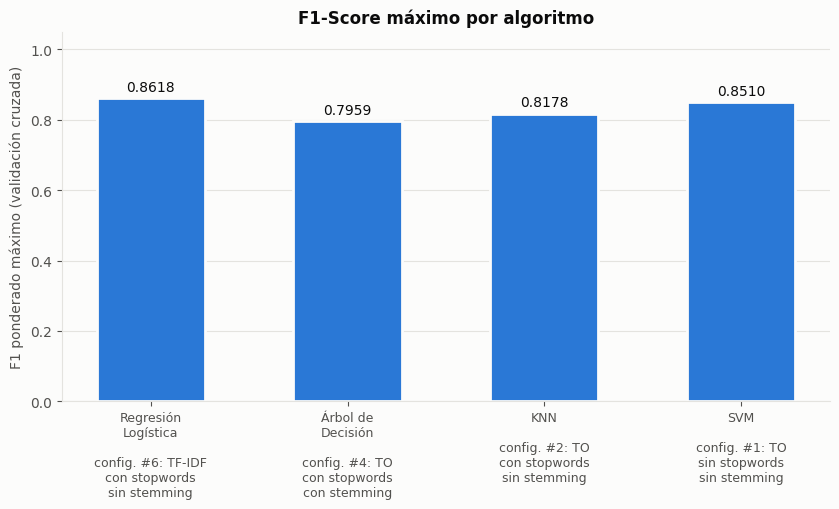

,#,POND,STOPWORDS,STEMMING,CV F1,Test F1
ALGORITMO,,,,,,
REGRESIÓN LOGÍSTICA,6,TF-IDF,True,False,0.861765,0.849386
ÁRBOLES DE DECISIÓN,4,TO,True,True,0.795940,0.790471
K VECINOS MÁS CERCANOS,2,TO,True,False,0.817812,0.786407
MÁQUINA DE VECTORES DE SOPORTE,1,TO,False,False,0.851002,0.850160


In [8]:
idx_max = resultados.groupby("ALGORITMO", sort=False)["CV F1"].idxmax()
maximos = resultados.loc[idx_max].set_index("ALGORITMO").loc[list(ALGORITMOS)]

etiquetas = []
for nombre, (_, fila) in zip(nombres, maximos.iterrows()):
    sw = "con stopwords" if fila["STOPWORDS"] else "sin stopwords"
    st = "con stemming" if fila["STEMMING"] else "sin stemming"
    etiquetas.append(f"{nombre}\n\nconfig. #{fila['#']}: {fila['POND']}\n{sw}\n{st}")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
barras = ax.bar(range(len(etiquetas)), maximos["CV F1"], width=0.55, color=SERIES[0], edgecolor=SUPERFICIE, linewidth=2)
ax.bar_label(barras, fmt="%.4f", padding=3, color=TINTA)
ax.set_xticks(range(len(etiquetas)), etiquetas, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 ponderado máximo (validación cruzada)")
ax.set_title("F1-Score máximo por algoritmo")
plt.tight_layout()
plt.savefig(RESULTADOS / "10_f1_maximo_por_algoritmo.png", dpi=150)
plt.show()
maximos[["#", "POND", "STOPWORDS", "STEMMING", "CV F1", "Test F1"]]

### 5.2 F1-Score medio por ponderación y algoritmo

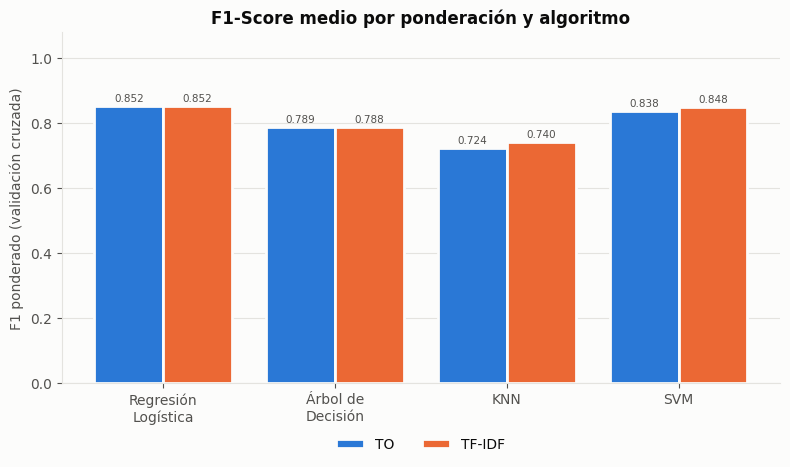

POND,TO,TF-IDF
ALGORITMO,,
REGRESIÓN LOGÍSTICA,0.8524,0.8518
ÁRBOLES DE DECISIÓN,0.7889,0.7878
K VECINOS MÁS CERCANOS,0.7240,0.7404
MÁQUINA DE VECTORES DE SOPORTE,0.8385,0.8480


In [9]:
por_ponderacion = (resultados.pivot_table(index="ALGORITMO", columns="POND", values="CV F1", aggfunc="mean")
                             .loc[list(ALGORITMOS), ["TO", "TF-IDF"]])

fig, ax = plt.subplots(figsize=(8, 4.8))
barras_agrupadas(ax, por_ponderacion, ["TO", "TF-IDF"], SERIES[:2])
ax.set_title("F1-Score medio por ponderación y algoritmo")
plt.tight_layout()
plt.savefig(RESULTADOS / "10_f1_medio_por_ponderacion.png", dpi=150)
plt.show()
por_ponderacion.round(4)

### 5.3 F1-Score medio por técnica de reducción y algoritmo

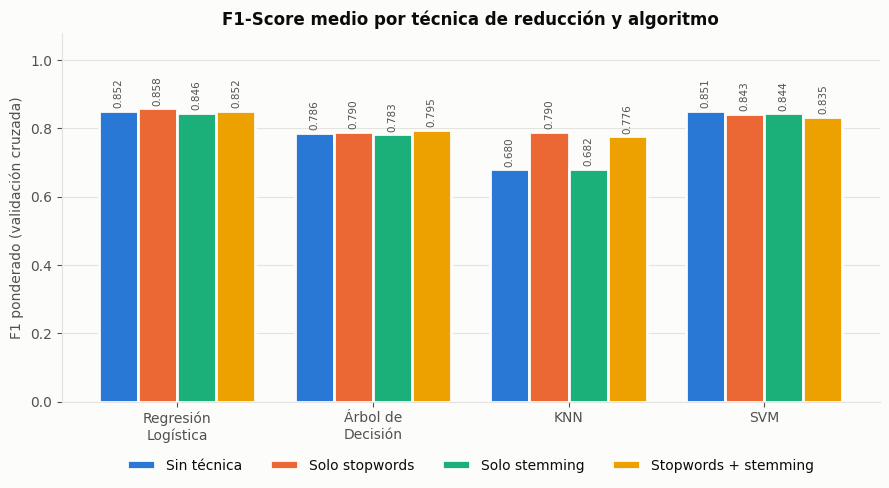

REDUCCIÓN,Sin técnica,Solo stopwords,Solo stemming,Stopwords + stemming
ALGORITMO,,,,
REGRESIÓN LOGÍSTICA,0.8524,0.8584,0.8459,0.8517
ÁRBOLES DE DECISIÓN,0.7861,0.7895,0.7825,0.7952
K VECINOS MÁS CERCANOS,0.6803,0.7897,0.6824,0.7764
MÁQUINA DE VECTORES DE SOPORTE,0.8506,0.8429,0.8444,0.8348


In [10]:
REDUCCIONES = {(False, False): "Sin técnica", (True, False): "Solo stopwords",
               (False, True): "Solo stemming", (True, True): "Stopwords + stemming"}
resultados["REDUCCIÓN"] = [REDUCCIONES[(sw, st)] for sw, st in zip(resultados["STOPWORDS"], resultados["STEMMING"])]
por_reduccion = (resultados.pivot_table(index="ALGORITMO", columns="REDUCCIÓN", values="CV F1", aggfunc="mean")
                           .loc[list(ALGORITMOS), list(REDUCCIONES.values())])

fig, ax = plt.subplots(figsize=(9, 5))
barras_agrupadas(ax, por_reduccion, list(REDUCCIONES.values()), SERIES)
ax.set_title("F1-Score medio por técnica de reducción y algoritmo")
plt.tight_layout()
plt.savefig(RESULTADOS / "10_f1_medio_por_reduccion.png", dpi=150)
plt.show()
por_reduccion.round(4)

- Los modelos lineales son los mejores: Regresión Logística (0,8618) y SVM (0,8510). KNN llega a 0,8178 y el Árbol a 0,7959.
- La ponderación casi no cambia el resultado; TF-IDF solo ayuda algo a KNN y al SVM.
- Quitar stopwords sube el F1 de KNN de 0,680 a 0,790. El stemming no mejora a ningún algoritmo.

## 6. Resultados en el 20 % de test

In [11]:
tabla_test = tabla_pdf("Test", ["Precision", "Recall", "F1"])
tabla_test.to_csv(RESULTADOS / "10_tabla_pdf_test.csv", encoding="utf-8")
(tabla_test.style.format("{:.4f}")
           .highlight_max(subset=columnas_f1, color="#cde2fb"))

In [12]:
comparacion = resultados[["#", "POND", "STOPWORDS", "STEMMING", "ALGORITMO", "CV F1", "CV F1 desv.", "Test F1"]].copy()
comparacion["diferencia (Test - CV)"] = comparacion["Test F1"] - comparacion["CV F1"]
print(f"Diferencia media entre test y validación cruzada: {comparacion['diferencia (Test - CV)'].mean():+.4f}")
print(f"Diferencia máxima (en valor absoluto): {comparacion['diferencia (Test - CV)'].abs().max():.4f}")
comparacion.sort_values("CV F1", ascending=False).head(8).round(4)

Diferencia media entre test y validación cruzada: -0.0064
Diferencia máxima (en valor absoluto): 0.0314


,#,POND,STOPWORDS,STEMMING,ALGORITMO,CV F1,CV F1 desv.,Test F1,diferencia (Test - CV)
20,6,TF-IDF,True,False,REGRESIÓN LOGÍSTICA,0.8618,0.0114,0.8494,-0.0124
0,1,TO,False,False,REGRESIÓN LOGÍSTICA,0.8566,0.0185,0.8491,-0.0075
28,8,TF-IDF,True,True,REGRESIÓN LOGÍSTICA,0.8553,0.0171,0.8581,0.0028
4,2,TO,True,False,REGRESIÓN LOGÍSTICA,0.8551,0.0162,0.8667,0.0116
3,1,TO,False,False,MÁQUINA DE VECTORES DE SOPORTE,0.8510,0.0177,0.8502,-0.0008
19,5,TF-IDF,False,False,MÁQUINA DE VECTORES DE SOPORTE,0.8502,0.0147,0.8433,-0.0069
8,3,TO,False,True,REGRESIÓN LOGÍSTICA,0.8499,0.0191,0.8511,0.0012
23,6,TF-IDF,True,False,MÁQUINA DE VECTORES DE SOPORTE,0.8491,0.0142,0.8551,0.0060


## 7. Mejor modelo

Mejor modelo: REGRESIÓN LOGÍSTICA con la configuración #6 (TF-IDF, stopwords=True, stemming=False)
F1 ponderado: 0.8618 en validación cruzada, 0.8494 en test

              precision    recall  f1-score   support

   Falso (0)     0.9227    0.7650    0.8365       515
  Verdad (1)     0.7993    0.9359    0.8623       515

    accuracy                         0.8505      1030
   macro avg     0.8610    0.8505    0.8494      1030
weighted avg     0.8610    0.8505    0.8494      1030



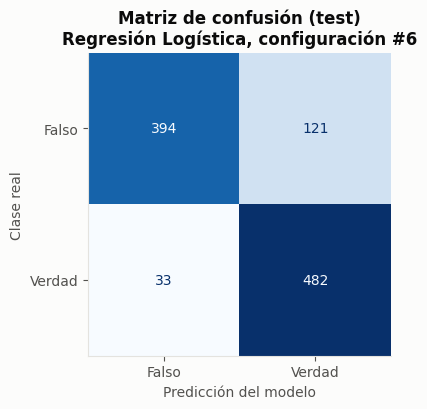

In [13]:
mejor = resultados.loc[resultados["CV F1"].idxmax()]
config_mejor = {c: mejor[c] for c in ["#", "POND", "STOPWORDS", "STEMMING"]}
print(f"Mejor modelo: {mejor['ALGORITMO']} con la configuración #{mejor['#']} "
      f"({mejor['POND']}, stopwords={mejor['STOPWORDS']}, stemming={mejor['STEMMING']})")
print(f"F1 ponderado: {mejor['CV F1']:.4f} en validación cruzada, {mejor['Test F1']:.4f} en test\n")

modelo_mejor = construir_modelo(config_mejor, mejor["ALGORITMO"])
modelo_mejor.fit(X_train, y_train)
y_pred = modelo_mejor.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Falso (0)", "Verdad (1)"], digits=4))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Falso", "Verdad"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.grid(False)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión (test)\n{NOMBRE_CORTO[mejor['ALGORITMO']].replace(chr(10), ' ')}, configuración #{mejor['#']}")
plt.tight_layout()
plt.savefig(RESULTADOS / "10_matriz_confusion_mejor.png", dpi=150)
plt.show()

Términos con más peso hacia cada clase.

In [14]:
clasificador = modelo_mejor.named_steps["clasificador"]
if hasattr(clasificador, "coef_"):
    terminos = modelo_mejor.named_steps["vectorizador"].get_feature_names_out()
    coeficientes = pd.Series(clasificador.coef_.ravel(), index=terminos).sort_values()
    terminos_clave = pd.DataFrame({
        "hacia FALSA": coeficientes.head(15).index, "coef. falsa": coeficientes.head(15).values.round(3),
        "hacia VERDADERA": coeficientes.tail(15).index[::-1], "coef. verdadera": coeficientes.tail(15).values[::-1].round(3),
    })
    terminos_clave.to_csv(RESULTADOS / "10_terminos_clave_mejor.csv", index=False, encoding="utf-8")
else:
    terminos_clave = "El mejor modelo no es lineal: no tiene coeficientes por término."
terminos_clave

,hacia FALSA,coef. falsa,hacia VERDADERA,coef. verdadera
0,equo,-6.683,podemos,5.261
1,bng,-5.343,sanchez,4.773
2,cristina narbona,-3.498,psoe,2.942
3,narbona,-3.449,erc,2.866
4,eaj pnv,-3.339,ayuso,2.846
5,eaj,-3.339,casado,2.829
6,cristina,-3.174,pp,2.684
7,per,-3.120,vox,2.611
8,canaria,-2.997,iglesias,2.561
9,pnv,-2.957,unidas podemos,1.894


El error más común es clasificar noticias falsas como verdaderas (121 de 515 en test). Los términos que más indican falsedad son partidos poco frecuentes en estas noticias (Equo, BNG, EAJ-PNV, Coalición Canaria), lo que refleja cómo se fabricaron las falsas del corpus curado.

## 8. Acierto por fuente

Predicciones de validación cruzada sobre todo el corpus, separadas por fuente, para comparar las falsas del corpus curado con los bulos reales del scraping.

In [15]:
pred_oof = cross_val_predict(construir_modelo(config_mejor, mejor["ALGORITMO"]), X, y, cv=validacion, n_jobs=-1)
corpus["acierto"] = pred_oof == y

por_fuente = (corpus.groupby(["fuente", "clase"])["acierto"]
                    .agg(documentos="size", aciertos="sum", accuracy="mean")
                    .reindex([("curado", "Verdad"), ("curado", "Falso"), ("eldiario", "Verdad"),
                              ("maldita", "Falso"), ("newtral", "Falso")]))
por_fuente["accuracy"] = por_fuente["accuracy"].round(4)
por_fuente.to_csv(RESULTADOS / "10_acierto_por_fuente.csv", encoding="utf-8")
por_fuente

documentos  aciertos  accuracy
fuente   clase                                 
curado   Verdad        2500      2370    0.9480
         Falso         2500      2003    0.8012
eldiario Verdad          75        73    0.9733
maldita  Falso           38        13    0.3421
newtral  Falso           37        16    0.4324

In [16]:
errores_scraping = corpus[(corpus["fuente"] != "curado") & ~corpus["acierto"]]
print(f"Noticias del scraping mal clasificadas: {len(errores_scraping)} de 150")
errores_scraping[["doc_id", "clase", "n_palabras_limpio", "texto_limpio"]].head(10)

Noticias del scraping mal clasificadas: 48 de 150


,doc_id,clase,n_palabras_limpio,texto_limpio
2528,eldiario_0029,Verdad,41,la izquierda impulsa su hoja de ruta tras el paso atras de yolanda diaz toca pisar mucho territorio movimiento sumar...
2540,eldiario_0041,Verdad,40,dimite carlos martin urriza uno de los dos coordinadores de movimiento sumar deja sus responsabilidades en el partid...
5076,maldita_0002,Falso,14,los germenes no existen como afirma pete hegseth nominado secretario de defensa por trump
5079,maldita_0005,Falso,17,el logo de la plataforma españa catolica fundada por ex miembros de pp y vox dice pec
5081,maldita_0007,Falso,16,el presidente de iran ebrahim raisi ha sobrevivido al accidente de helicoptero en el que viajaba
5083,maldita_0009,Falso,23,alberto nuñez feijoo lider del pp aparece en una fotografia con el empresario victor de aldama señalado por corrupci...
5084,maldita_0010,Falso,13,el tsjm imputara a pedro sanchez por ocultar el coste de sus vacaciones
5086,maldita_0012,Falso,12,de los ministros del ultimo gobierno de aznar estan imputados por corrupcion
5088,maldita_0014,Falso,15,pedro sanchez anuncia penas de carcel para quien ataque a los migrantes en redes sociales
5089,maldita_0015,Falso,10,joe biden se queda dormido durante una entrevista en directo


El modelo acierta el 80 % de las falsas del corpus curado, pero solo el 39 % de los bulos reales de Maldita y Newtral.

## 9. Conclusiones

- Mejor modelo: Regresión Logística con TF-IDF y stopwords, sin stemming (F1 = 0,8618 en validación cruzada y 0,8494 en test).
- Los modelos lineales superan a KNN y al Árbol de Decisión.
- Las stopwords reducen el vocabulario un 91 % sin perder rendimiento; el stemming no aporta.
- El F1 en test es parecido al de la validación cruzada, así que no hay sobreajuste.
- El modelo no generaliza a bulos reales: aprende cómo se fabricaron las falsas del corpus curado.